In [5]:
# !pip install pandas numpy scikit-learn matplotlib seaborn wordcloud
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report

In [6]:
df = pd.read_csv('tweet_data.csv')[['created_at', 'username', 'full_text']].dropna(subset=['full_text'])
print('Jumlah tweet:', len(df))
df.head()

Jumlah tweet: 300


,created_at,username,full_text
0,2026-11-01,user0,"Polusi turun, kondisi membaik #udara @u0 http:..."
1,2026-11-02,user1,"Udara bersih, langit cerah, lega banget #udara..."
2,2026-11-03,user2,"Polusi parah, udara berbahaya #udara @u2 http:..."
3,2026-11-04,user3,"Udara bersih, langit cerah, lega banget #udara..."
4,2026-11-05,user4,Pemerintah rapat soal udara #udara @u4 http://...


In [7]:
def clean_text(text):
    text = str(text)
    text = re.sub(r'http\S+|www\.\S+', ' ', text)   # URL
    text = re.sub(r'@\w+', ' ', text)               # mention
    text = re.sub(r'#\w+', ' ', text)               # hashtag
    text = re.sub(r'\d+', ' ', text)                # angka
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)        # simbol/emoji
    text = text.lower()                              # case folding
    return re.sub(r'\s+', ' ', text).strip()        # spasi berlebih

df['clean_text'] = df['full_text'].apply(clean_text)
df = df[df['clean_text'].str.len() > 0].reset_index(drop=True)
df[['full_text', 'clean_text']].head()

,full_text,clean_text
0,"Polusi turun, kondisi membaik #udara @u0 http:...",polusi turun kondisi membaik
1,"Udara bersih, langit cerah, lega banget #udara...",udara bersih langit cerah lega banget
2,"Polusi parah, udara berbahaya #udara @u2 http:...",polusi parah udara berbahaya
3,"Udara bersih, langit cerah, lega banget #udara...",udara bersih langit cerah lega banget
4,Pemerintah rapat soal udara #udara @u4 http://...,pemerintah rapat soal udara


In [8]:
POSITIF = {'baik','bersih','sehat','segar','aman','lega','membaik','turun','pulih','sejuk','bantuan',
           'peduli','bagus','cerah','jernih','hijau','solusi','berhasil','terkendali','nyaman','selamat'}
NEGATIF = {'buruk','polusi','kotor','bahaya','berbahaya','parah','sesak','batuk','ispa','asap','kabut',
           'kabur','tercemar','pencemaran','tidak sehat','naik','memburuk','rusak','sakit','mengganggu',
           'pekat','debu','menyengat','khawatir','gawat'}

def label_sentiment(text):
    tokens = text.split()
    joined = ' ' + text + ' '
    pos = sum(t in POSITIF for t in tokens)
    neg = sum(t in NEGATIF for t in tokens)
    for w in POSITIF | NEGATIF:          # frasa lebih dari satu kata
        if ' ' in w and f' {w} ' in joined:
            if w in POSITIF: pos += 1
            else: neg += 1
    if pos > neg: return 'positif'
    if neg > pos: return 'negatif'
    return 'netral'

df['sentimen'] = df['clean_text'].apply(label_sentiment)
df.to_csv('tweet_data_berlabel.csv', index=False)
df[['clean_text', 'sentimen']].head()

,clean_text,sentimen
0,polusi turun kondisi membaik,positif
1,udara bersih langit cerah lega banget,positif
2,polusi parah udara berbahaya,negatif
3,udara bersih langit cerah lega banget,positif
4,pemerintah rapat soal udara,netral


sentimen
positif     98
netral     107
negatif     95
Name: count, dtype: int64


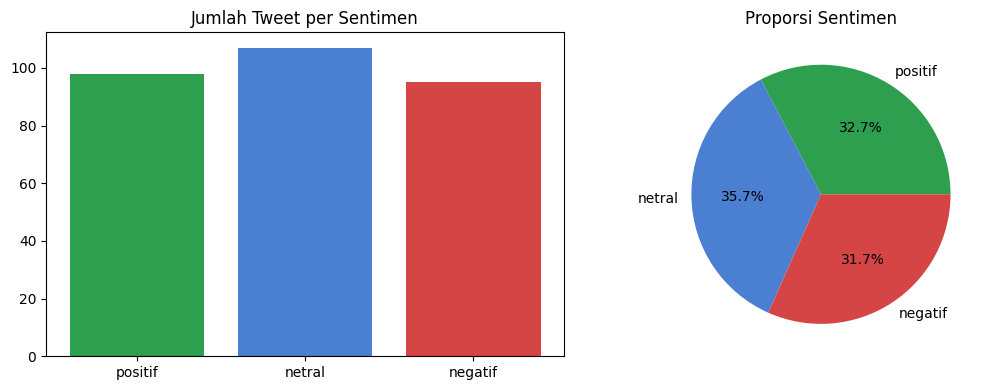

In [9]:
order = ['positif', 'netral', 'negatif']
colors = ['#2e9e4f', '#4a7fd1', '#d64545']
counts = df['sentimen'].value_counts().reindex(order).fillna(0).astype(int)
print(counts)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(counts.index, counts.values, color=colors); ax[0].set_title('Jumlah Tweet per Sentimen')
ax[1].pie(counts.values, labels=counts.index, autopct='%1.1f%%', colors=colors); ax[1].set_title('Proporsi Sentimen')
plt.tight_layout(); plt.show()

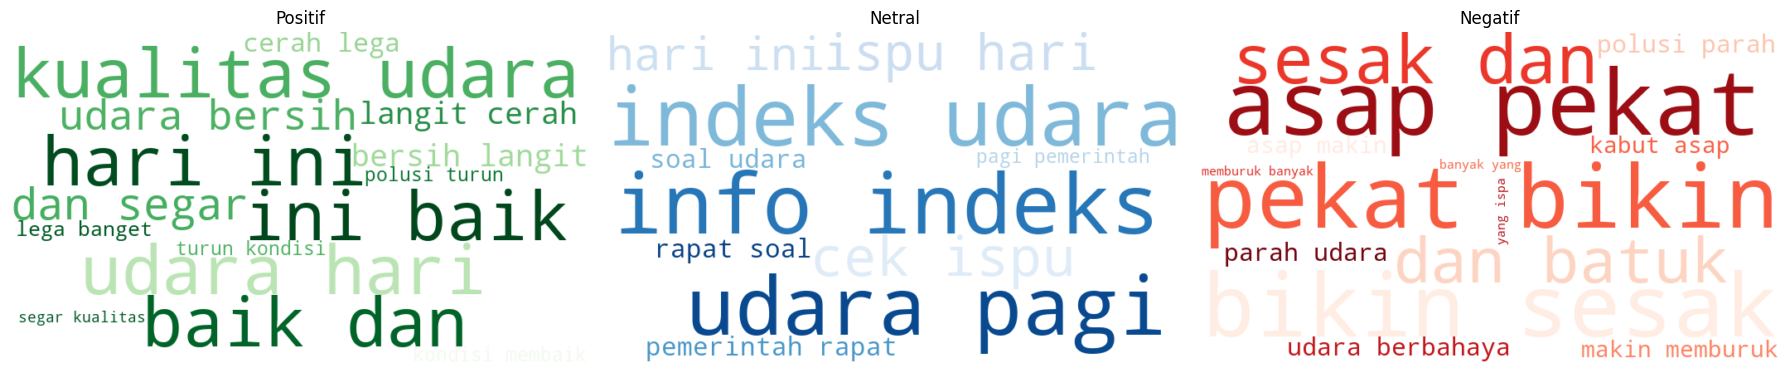

In [10]:
cmaps = {'positif': 'Greens', 'netral': 'Blues', 'negatif': 'Reds'}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, s in zip(axes, order):
    text = ' '.join(df.loc[df['sentimen'] == s, 'clean_text'])
    ax.set_title(s.capitalize()); ax.axis('off')
    if text.strip():
        ax.imshow(WordCloud(width=700, height=400, background_color='white', colormap=cmaps[s],
                            max_words=100).generate(text), interpolation='bilinear')
plt.tight_layout(); plt.show()

In [11]:
strat = df['sentimen'] if df['sentimen'].value_counts().min() >= 2 else None
X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'], df['sentimen'], test_size=0.2, random_state=42, stratify=strat)

vec = TfidfVectorizer(max_features=3000, ngram_range=(1, 2))
Xtr = vec.fit_transform(X_train)
Xte = vec.transform(X_test)

mlp = MLPClassifier(hidden_layer_sizes=(100,), activation='relu', solver='adam',
                    max_iter=300, random_state=42)
mlp.fit(Xtr, y_train)
y_pred = mlp.predict(Xte)
print('Data latih:', len(y_train), '| Data uji:', len(y_test))

Data latih: 240 | Data uji: 60


In [12]:
acc = accuracy_score(y_test, y_pred)
p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, average='weighted', zero_division=0)
ringkasan = pd.DataFrame({'Metrik': ['Akurasi', 'Presisi (weighted)', 'Recall (weighted)', 'F1-Score (weighted)'],
                          'Nilai': [acc, p, r, f]}).round(4)
display(ringkasan)
print(classification_report(y_test, y_pred, zero_division=0))

,Metrik,Nilai
0,Akurasi,1.0
1,Presisi (weighted),1.0
2,Recall (weighted),1.0
3,F1-Score (weighted),1.0


              precision    recall  f1-score   support

     negatif       1.00      1.00      1.00        19
      netral       1.00      1.00      1.00        21
     positif       1.00      1.00      1.00        20

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60



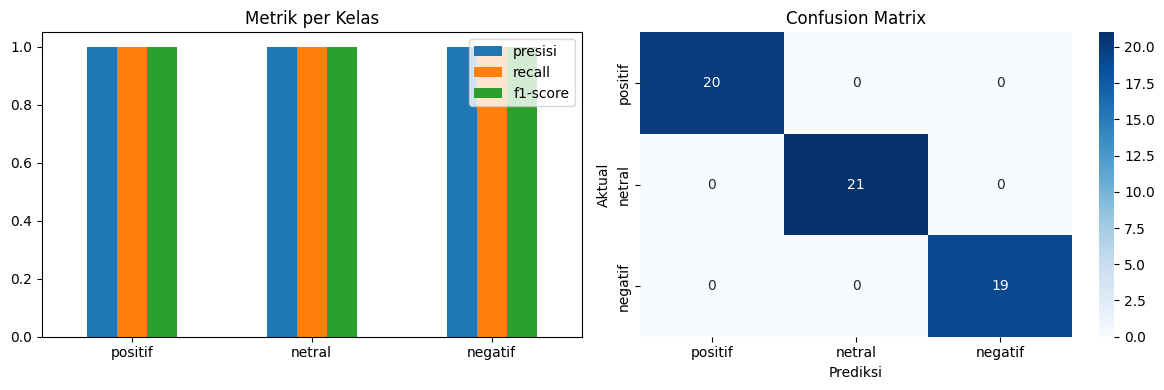

,presisi,recall,f1-score,support
positif,1.0,1.0,1.0,20
netral,1.0,1.0,1.0,21
negatif,1.0,1.0,1.0,19


In [13]:
labels_order = [c for c in order if c in set(df['sentimen'])]
pc, rc, fc, sc = precision_recall_fscore_support(y_test, y_pred, labels=labels_order, zero_division=0)
tabel = pd.DataFrame({'presisi': pc, 'recall': rc, 'f1-score': fc, 'support': sc}, index=labels_order)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
tabel[['presisi', 'recall', 'f1-score']].plot(kind='bar', ax=ax[0], rot=0)
ax[0].set_ylim(0, 1.05); ax[0].set_title('Metrik per Kelas')
cm = confusion_matrix(y_test, y_pred, labels=labels_order)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels_order, yticklabels=labels_order, ax=ax[1])
ax[1].set_xlabel('Prediksi'); ax[1].set_ylabel('Aktual'); ax[1].set_title('Confusion Matrix')
plt.tight_layout(); plt.show()
tabel.round(3)

In [14]:
EMOJI = {'positif': '😊', 'netral': '😐', 'negatif': '😠'}

def prediksi(teks):
    bersih = clean_text(teks)
    proba = mlp.predict_proba(vec.transform([bersih]))[0]
    hasil = mlp.classes_[int(np.argmax(proba))]
    print(f'Teks bersih : {bersih}')
    print(f'Sentimen    : {EMOJI[hasil]} {hasil.upper()}')
    for k, v in zip(mlp.classes_, proba):
        print(f'  {k:8s}: {v:.3f}')

prediksi('Kualitas udara hari ini membaik, langit cerah dan terasa segar')
prediksi('Asap pekat bikin sesak dan batuk, udara berbahaya')

Teks bersih : kualitas udara hari ini membaik langit cerah dan terasa segar
Sentimen    : 😊 POSITIF
  negatif : 0.002
  netral  : 0.006
  positif : 0.992
Teks bersih : asap pekat bikin sesak dan batuk udara berbahaya
Sentimen    : 😠 NEGATIF
  negatif : 0.998
  netral  : 0.001
  positif : 0.001
